In [71]:
import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import math
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
from torch import nn
import torch.optim as optim
import torch.nn.functional as F



In [72]:
T_final = 30.0
dt = 0.01
N_T = int(T_final/dt+1)
t = torch.linspace(0.0,T_final,N_T)

In [73]:
a_1 = 1.0+0.15*torch.cos(0.08*t)
a_2 = 0.3+0.05*torch.sin(0.04*t)

omega_1 = 2*torch.pi*(1.2+0.08*torch.sin(0.03*t))
omega_2 = 2*torch.pi*(0.25+0.02*torch.cos(0.02*t))

theta_1 = 2*torch.pi*(1.2*t-0.08/0.03*torch.cos(0.03*t)+0.08/0.03)
theta_2 = 2*torch.pi*(0.25*t+torch.sin(0.02*t))


noise_sigma = 0.1
mvn = MultivariateNormal(torch.zeros(N_T),noise_sigma**2*torch.eye(N_T))
noise = mvn.sample()

def y_1(s):
    
    #waveform_1 = torch.cos(s)+0.45*torch.cos(2*s)-0.2*torch.sin(2*s)
    waveform_1 = torch.cos(s)

    
    return waveform_1

def y_2(s):
    
    #waveform_2 = torch.cos(s)+0.2*torch.sin(2*s)
    waveform_2 = torch.cos(s)

    
    return waveform_2

v_1 = a_1*y_1(theta_1)
v_2 = a_2*y_2(theta_2)

v = v_1+v_2+noise

In [143]:
def Gabor(t,tau,omega,theta,alpha):
    #g = (2/torch.pi)**(1/4)*torch.sqrt(omega/alpha)*torch.exp(-((t-tau)*omega/alpha)**2)*torch.cos(omega*(t-tau)+theta)
    g = torch.exp(-((t-tau)*omega/alpha)**2)*torch.cos(omega*(t-tau)+theta)

    return g

sample_rate_tau = 100
tau = t[::sample_rate_tau]
sample_size_tau = len(tau)

omega_min = 0.1*2*torch.pi
omega_max = 3*2*torch.pi
sample_size_omega = 100

omega = torch.linspace(omega_min, omega_max, sample_size_omega)
alpha = 2*torch.pi*2

sample_size_theta = 64
theta = torch.linspace(-torch.pi,torch.pi-torch.pi/sample_size_theta,sample_size_theta)

In [144]:
K = torch.zeros(N_T,N_T)

for i in range(len(tau)):
    for j in range(sample_size_omega):
        for k in range(sample_size_theta):
            chi = Gabor(t,tau[i],omega[j],theta[k],alpha)
            K += torch.outer(chi,chi)
            
nugget = 10**-5
Kv = torch.linalg.solve(K+nugget*torch.eye(N_T),v)

In [145]:

n_tau = len(tau)
n_omega = len(omega)

tau_grid_2d, omega_grid_2d = torch.meshgrid(tau, omega, indexing="ij")   # (n_tau, n_omega)

tau_ext = tau_grid_2d.reshape(-1, 1)      # (P,1)
omega_ext = omega_grid_2d.reshape(-1, 1)  # (P,1)

dt_grid = t[None, :] - tau_ext            # (P, N)

# same Gaussian envelope you are already using
#gauss = ((2 / torch.pi**3) ** 0.25) * torch.sqrt(omega_ext / alpha) * torch.exp(-((omega_ext * dt_grid / alpha) ** 2))
gauss = torch.exp(-((omega_ext * dt_grid / alpha) ** 2))
phase0 = omega_ext * dt_grid

g_cos = gauss * torch.cos(phase0)   # (P, N)
g_sin = gauss * torch.sin(phase0)   # (P, N)

A_flat = g_cos @ Kv   # (P,)
B_flat = g_sin @ Kv   # (P,)

A = A_flat.reshape(n_tau, n_omega)
B = B_flat.reshape(n_tau, n_omega)

I = torch.eye(N_T, dtype=t.dtype, device=t.device)
K_reg = K + nugget * I

# solve K x = g^T for all atoms at once
# g_cos, g_sin are (P, N_T)

Kg_cos = torch.linalg.solve(K_reg, g_cos.T).T   # (P, N_T)
Kg_sin = torch.linalg.solve(K_reg, g_sin.T).T   # (P, N_T)

N_cos = torch.sum(g_cos * Kg_cos, dim=1)        # (P,)
N_sin = torch.sum(g_sin * Kg_sin, dim=1)        # (P,)
N_avg = 0.5 * (N_cos + N_sin)

E_norm_flat = (A_flat**2 + B_flat**2) / (N_avg + 1e-12)
E_norm = E_norm_flat.reshape(n_tau, n_omega)

theta_e = torch.atan2(-B, A)        # shape: (n_tau, n_omega)
E_tau_omega = A**2 + B**2        

In [146]:
def unwrap_phase(x, dim=0, period=2*math.pi):
    dx = torch.diff(x, dim=dim)
    half = period / 2
    dx_wrapped = (dx + half) % period - half

    correction = dx_wrapped - dx
    correction = torch.where(torch.abs(dx) < half, torch.zeros_like(correction), correction)

    cumsum = torch.cumsum(correction, dim=dim)

    pad_shape = list(x.shape)
    pad_shape[dim] = 1
    pad = torch.zeros(pad_shape, dtype=x.dtype, device=x.device)

    correction_full = torch.cat([pad, cumsum], dim=dim)
    return x + correction_full

theta_e_unwrapped = unwrap_phase(theta_e, dim=0)

def smooth_along_tau(x, win=5):
    # x shape: (n_tau, n_omega)
    pad = win // 2
    xT = x.T.unsqueeze(1)  # (n_omega, 1, n_tau)
    kernel = torch.ones(1, 1, win, device=x.device, dtype=x.dtype) / win
    x_pad = torch.nn.functional.pad(xT, (pad, pad), mode="replicate")
    y = torch.nn.functional.conv1d(x_pad, kernel)
    return y.squeeze(1).T

theta_e_smooth = smooth_along_tau(theta_e_unwrapped, win=5)

w_e = torch.zeros_like(theta_e_smooth)

# nonuniform-safe finite differences
w_e[0] = (theta_e_smooth[1] - theta_e_smooth[0]) / (tau[1] - tau[0])
w_e[-1] = (theta_e_smooth[-1] - theta_e_smooth[-2]) / (tau[-1] - tau[-2])

tau_diff = (tau[2:] - tau[:-2]).unsqueeze(1)   # (n_tau-2,1)
w_e[1:-1] = (theta_e_smooth[2:] - theta_e_smooth[:-2]) / tau_diff

nearest_idx = torch.argmin(
    torch.abs(w_e[..., None] - omega[None, None, :]),
    dim=2
)  # shape: (n_tau, n_omega)

S = torch.full_like(E_tau_omega, float("-inf"))

# scatter max along omega-axis
S.scatter_reduce_(
    dim=1,
    index=nearest_idx,
    src=E_tau_omega,
    reduce="amax",
    include_self=True
)

S[S == float("-inf")] = 0.0

In [147]:
ridge_idx = torch.zeros((n_tau, 2), dtype=torch.long)

for i in range(n_tau):
    vals = S[i].clone()

    j1 = torch.argmax(vals)
    ridge_idx[i, 0] = j1

    band = 3
    left = max(0, j1 - band)
    right = min(n_omega, j1 + band + 1)
    vals[left:right] = -float("inf")

    j2 = torch.argmax(vals)
    ridge_idx[i, 1] = j2

ridge_idx, _ = torch.sort(ridge_idx, dim=1)
omega_ridges = omega[ridge_idx]

In [148]:
def Gabor_cos(t,tau,omega,alpha):
    #g_cos = (2/torch.pi)**(1/4)*torch.sqrt(omega/alpha)*torch.exp(-((t-tau)*omega/alpha)**2)*torch.cos(omega*(t-tau))
    g_cos =torch.exp(-((t-tau)*omega/alpha)**2)*torch.cos(omega*(t-tau))

    return g_cos

def Gabor_sin(t,tau,omega,alpha):
    #g_sin = (2/torch.pi)**(1/4)*torch.sqrt(omega/alpha)*torch.exp(-((t-tau)*omega/alpha)**2)*torch.sin(omega*(t-tau))
    g_sin =torch.exp(-((t-tau)*omega/alpha)**2)*torch.sin(omega*(t-tau))

    return g_sin

In [149]:

n_tau, n_omega = S.shape

ridge_idx = torch.zeros((n_tau, 2), dtype=torch.long)

# ---------- helpers ----------

def smooth_ridges(x, win=7):
    """
    x: (n_tau, 2)
    smooth each ridge along tau
    """
    xT = x.T.unsqueeze(1)  # (2,1,n_tau)
    pad = win // 2
    kernel = torch.ones(1, 1, win, dtype=x.dtype, device=x.device) / win
    x_pad = F.pad(xT, (pad, pad), mode="replicate")
    y = F.conv1d(x_pad, kernel)
    return y.squeeze(1).T  # (n_tau, 2)


def build_soft_weights(S, omega, omega_ridges, ridge_win=7, sigma_bins=3.0,
                       quantile_keep=0.7, conf_sharpness=10.0):
    """
    Returns:
        w1_soft, w2_soft: (n_tau, n_omega)
        A1_mask, A2_mask: hard visualization masks only
        omega_ridges_smooth: smoothed ridges
    """
    # smooth ridge trajectories first
    omega_ridges_smooth = smooth_ridges(omega_ridges, win=ridge_win)

    # distances from each omega-bin to each ridge
    dist1 = torch.abs(omega[None, :] - omega_ridges_smooth[:, 0:1])   # (n_tau, n_omega)
    dist2 = torch.abs(omega[None, :] - omega_ridges_smooth[:, 1:2])   # (n_tau, n_omega)

    # softness scale in omega
    domega = omega[1] - omega[0]
    sigma_assign = sigma_bins * domega
    beta = 1.0 / (2.0 * sigma_assign**2)

    score1 = torch.exp(-beta * dist1**2)
    score2 = torch.exp(-beta * dist2**2)

    p1 = score1 / (score1 + score2 + 1e-12)
    p2 = 1.0 - p1

    # confidence from S so weak cells contribute less
    threshold = torch.quantile(S.reshape(-1), quantile_keep)
    sharpness = conf_sharpness / (threshold + 1e-12)
    conf = torch.sigmoid(sharpness * (S - threshold))

    w1_soft = conf * p1
    w2_soft = conf * p2

    # normalize so w1_soft + w2_soft = conf
    norm = w1_soft + w2_soft + 1e-12
    w1_soft = conf * w1_soft / norm
    w2_soft = conf * w2_soft / norm

    # only for visualization / debugging
    A1_mask = w1_soft > w2_soft
    A2_mask = w2_soft >= w1_soft

    return w1_soft, w2_soft, A1_mask, A2_mask, omega_ridges_smooth


def build_mode_kernels_soft(t, tau, omega, alpha, w1_soft, w2_soft,
                            eps_weight=1e-4):
    """
    Build K_1, K_2 using soft weights over (tau, omega).
    """
    N_T = len(t)
    K_1 = torch.zeros(N_T, N_T, dtype=t.dtype, device=t.device)
    K_2 = torch.zeros(N_T, N_T, dtype=t.dtype, device=t.device)

    tau_2d, omega_2d = torch.meshgrid(tau, omega, indexing="ij")
    params_2d = torch.stack([tau_2d.reshape(-1), omega_2d.reshape(-1)], dim=1)

    w1_flat = w1_soft.reshape(-1)
    w2_flat = w2_soft.reshape(-1)

    for idx in range(len(params_2d)):
        tau_val = params_2d[idx, 0]
        omega_val = params_2d[idx, 1]

        weight1 = w1_flat[idx]
        weight2 = w2_flat[idx]

        if (weight1 < eps_weight) and (weight2 < eps_weight):
            continue

        g_cos = Gabor_cos(t, tau_val, omega_val, alpha)
        g_sin = Gabor_sin(t, tau_val, omega_val, alpha)

        K_local = torch.outer(g_cos, g_cos) + torch.outer(g_sin, g_sin)

        if weight1 >= eps_weight:
            K_1 += weight1 * K_local

        if weight2 >= eps_weight:
            K_2 += weight2 * K_local

    return K_1, K_2


def recover_modes_from_soft_kernels(v, K_1, K_2, noise_sigma):
    """
    Recover w_1, w_2 from K_1, K_2.
    """
    N_T = len(v)
    I = torch.eye(N_T, dtype=v.dtype, device=v.device)

    K_full = K_1 + K_2
    c = torch.linalg.solve(K_full + noise_sigma**2 * I, v)

    w_1 = K_1 @ c
    w_2 = K_2 @ c
    w = w_1 + w_2

    return w_1, w_2, w, c, K_full

In [150]:
w1_soft, w2_soft, A1_mask, A2_mask, omega_ridges_smooth = build_soft_weights(
    S=S,
    omega=omega,
    omega_ridges=omega_ridges,
    ridge_win=7,
    sigma_bins=1.0,
    quantile_keep=0.5,
    conf_sharpness=10.0,
)

# Build K1, K2
K_1, K_2 = build_mode_kernels_soft(
    t=t,
    tau=tau,
    omega=omega,
    alpha=alpha,
    w1_soft=w1_soft,
    w2_soft=w2_soft,
    eps_weight=1e-4,
)

In [151]:
K_full = K_1+K_2

c = torch.linalg.solve(K_full+noise_sigma**2*torch.eye(N_T),v)

w_1 = K_1@c
w_2 = K_2@c

w = w_1+w_2


In [152]:
print("||v - w|| / ||v|| =", torch.norm(v - w) / torch.norm(v))
print("||v1 - w1|| / ||v1|| =", torch.norm(v_1 - w_1) / torch.norm(v_1))
print("||v2 - w2|| / ||v2|| =", torch.norm(v_2 - w_2) / torch.norm(v_2))
print("corr(w1, v2) =", torch.dot(w_1, v_2) / (torch.norm(w_1) * torch.norm(v_2) + 1e-12))
print("corr(w2, v1) =", torch.dot(w_2, v_1) / (torch.norm(w_2) * torch.norm(v_1) + 1e-12))

||v - w|| / ||v|| = tensor(0.1233)
||v1 - w1|| / ||v1|| = tensor(1.0289)
||v2 - w2|| / ||v2|| = tensor(3.2860)
corr(w1, v2) = tensor(0.0871)
corr(w2, v1) = tensor(0.9327)


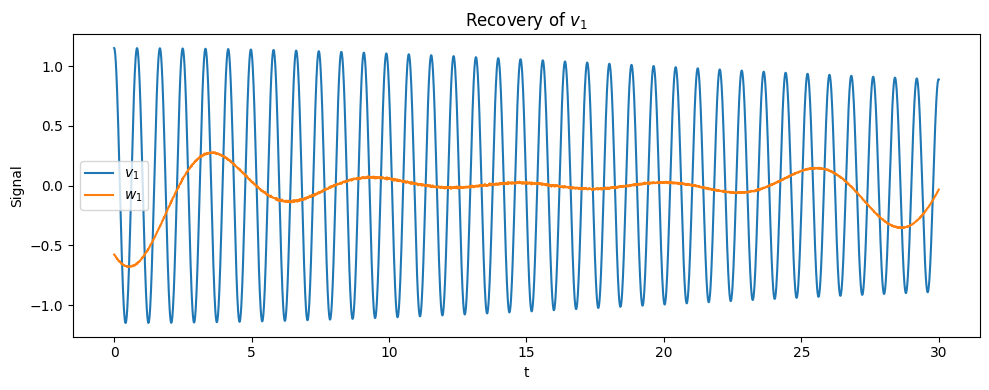

In [153]:
plt.figure(figsize=(10, 4))
plt.plot(t, v_1, label=r"$v_1$")
plt.plot(t, w_1, label=r"$w_1$")

plt.xlabel("t")
plt.ylabel("Signal")
plt.title(r"Recovery of $v_1$")
plt.legend()
plt.tight_layout()
plt.show()

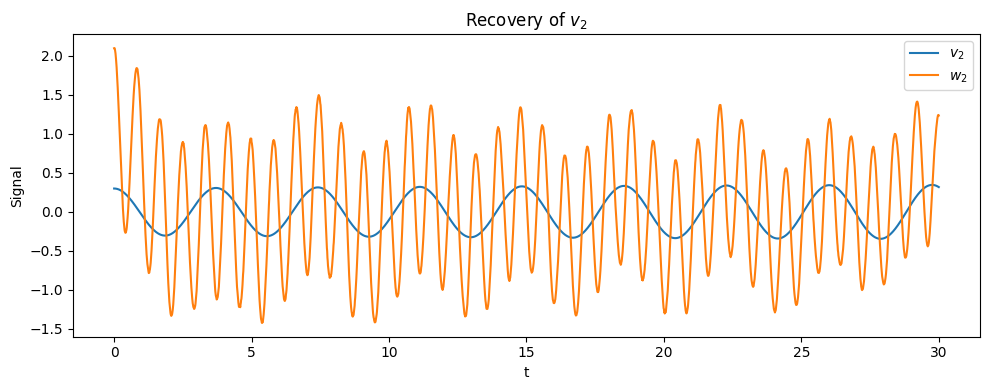

In [154]:
plt.figure(figsize=(10, 4))
plt.plot(t, v_2, label=r"$v_2$")
plt.plot(t, w_2, label=r"$w_2$")

plt.xlabel("t")
plt.ylabel("Signal")
plt.title(r"Recovery of $v_2$")
plt.legend()
plt.tight_layout()
plt.show()

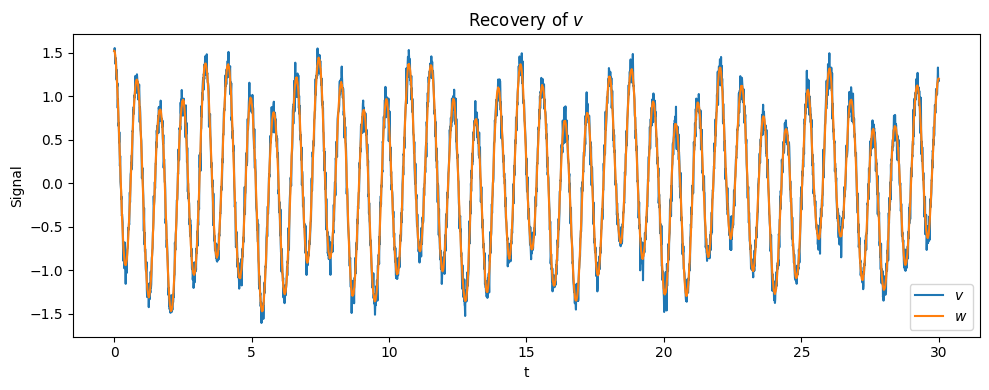

In [155]:
plt.figure(figsize=(10, 4))
plt.plot(t, v, label=r"$v$")
plt.plot(t, w, label=r"$w$")

plt.xlabel("t")
plt.ylabel("Signal")
plt.title(r"Recovery of $v$")
plt.legend()
plt.tight_layout()
plt.show()

In [156]:
omega1_true_tau = omega_1[::sample_rate_tau]
omega2_true_tau = omega_2[::sample_rate_tau]

print(torch.mean(torch.abs(omega_ridges[:, 0] - omega2_true_tau)))
print(torch.mean(torch.abs(omega_ridges[:, 1] - omega1_true_tau)))

tensor(1.0606)
tensor(6.0893)


In [157]:
print("ridge 1 Hz:", omega_ridges[:, 0] / (2 * torch.pi))
print("ridge 2 Hz:", omega_ridges[:, 1] / (2 * torch.pi))

ridge 1 Hz: tensor([0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000,
        0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000,
        0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000, 0.1000,
        0.1000, 0.1000, 0.1000, 0.1000])
ridge 2 Hz: tensor([0.3051, 0.3343, 0.3051, 0.3051, 0.2172, 0.2172, 0.2172, 0.2172, 0.2172,
        0.2172, 0.2172, 0.2172, 0.2465, 0.2465, 0.2758, 0.2172, 0.3636, 0.3929,
        0.3929, 0.4808, 0.3636, 0.2465, 0.2172, 0.2172, 0.2172, 0.2172, 0.2172,
        0.2172, 0.2172, 0.2465, 0.2172])


In [158]:
E_raw = A**2 + B**2
jmax = torch.argmax(E_raw, dim=1)
print("raw max Hz:", omega[jmax] / (2 * torch.pi))

raw max Hz: tensor([3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
        3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.])
